# Every box on the real slice (card #36)

jonas's scratch notebook. It runs each box of `main.ipynb` on real Companies House data instead of the tiny world, to see what works, what breaks and how long it takes.

**The data:** the query companies that part 1 of the 2021 crawl (#24) had finished when this ran. That is a fair sample of construction companies formed in 2021, not the final data; Jan counts part 2 separately in #62. No company formed in 2022 is crawled yet, so there is no test set here, and nothing below looks at one.

**Masking:** only display columns are shown. A director's name becomes a pseudonym, and birth dates never appear.

The notes under each box describe the run saved here: 438 query companies, the crawl's state at 15:04 on Saturday 14 November. What breaks is listed at the end.

This project is a prototype and is not financial advice.

In [1]:
# Setup: pick up changes to src/ without restarting, and make `import src` work from notebooks/
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "..")

import random
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import baseline, decide, evaluate, interface, real_slice, resolve
from src import evidence as ev

SEED = 42              # one seed for everything random, as in main.ipynb
random.seed(SEED)
np.random.seed(SEED)
COSTS = (10, 2, 1)     # the team's costs: a missed case, a wrong flag, asking
timings = {}           # seconds per step, shown at the end

## Data
`real_slice.load_slice()` reads the finished query companies from `data/raw/query_companies.csv` and runs the team's adapter over every raw file, with the schema checks. It keeps those companies as the slice, then labels and splits them with `label_failures` and `split`. Every other company in `data/raw` is a director's earlier company: evidence, never a query.

In [2]:
start = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:   # print the adapter's warnings without a file path
    warnings.simplefilter("always")
    mentions, claims, labels, left_out = real_slice.load_slice()
timings["load the slice: adapter, checks, labels"] = time.perf_counter() - start
for warning in caught:
    print("adapter warning:", warning.message)

print("mentions:", mentions["kind"].value_counts().to_dict(), "| claims:", len(claims))
print("query companies labelled:", len(labels), "| left out:", left_out if left_out else "none")
print("formed between", labels["formed_on"].min(), "and", labels["formed_on"].max())

# The team's label (insolvent or dissolved within 24 months), and insolvency only (count_dissolved=False)
labels["failed_insolvency"] = evaluate.label_failures(mentions, count_dissolved=False).loc[labels["company_id"]].to_numpy()
train = labels[labels["split"] == "train"]
validation = labels[labels["split"] == "validation"]
labels.groupby("split").agg(companies=("company_id", "size"), failed=("failed", "sum"),
                            share_failed=("failed", "mean"),
                            failed_through_insolvency=("failed_insolvency", "sum")).round(3)

adapter warning: 2 director records skipped: the resignation is dated before the appointment.
mentions: {'company': 4621, 'person': 2990} | claims: 2990
query companies labelled: 438 | left out: none
formed between 2021-01-02 and 2021-12-31


,companies,failed,share_failed,failed_through_insolvency
split,,,,
train,331,111,0.335,0
validation,107,26,0.243,0


**What it shows.** All 438 query companies could be labelled. Under the team's label, 111 of 331 failed in train and 26 of 107 in validation, and **none through liquidation or administration**: on this sample the label is dissolution only. Validation fails less often than train (24% against 34%), which matters for the line below.

## Baselines, on validation
The three baselines decide for the validation companies (formed Oct–Dec 2021), and `score_methods` scores them all the same way. A baseline flags a company when one of its directors is linked to a company that went insolvent in the 3 years before it was formed.

In [3]:
start = time.perf_counter()
baseline_decisions = baseline.run_all(list(validation["company_id"]), mentions, claims)
timings["three baselines on validation"] = time.perf_counter() - start
evaluate.score_methods(baseline_decisions, validation)

,method,companies,failed,flags,false_flags,misses,precision,recall,not_enough_evidence,pr_auc
0,flag_nothing,107,26,0,0,26,NaN,0.000000,0.0,None
1,same_name,107,26,2,1,25,0.5,0.038462,0.0,None
2,officer_links,107,26,0,0,26,NaN,0.000000,0.0,None


In [4]:
# The same baselines with no 3-year window (100 years), to compare with the decision layer, which has none
no_window = baseline.run_all(list(validation["company_id"]), mentions, claims, window_years=100)
evaluate.score_methods(no_window, validation)[["method", "flags", "false_flags", "misses", "precision", "recall"]]

,method,flags,false_flags,misses,precision,recall
0,flag_nothing,0,0,26,NaN,0.000000
1,same_name,12,9,23,0.25,0.115385
2,officer_links,6,6,26,0.00,0.000000


**What it shows.** With their 3-year window, `same_name` flags 2 validation companies (1 of them failed) and `officer_links` flags none. With no window, `officer_links` flags 6, all of them false flags, and `same_name` flags 12, 9 of them false. The decision layer has no window, so the baselines and our method don't yet judge by the same rule.

## Blocking (#83)
Two person records are a candidate pair when they have the same surname and first initial, or the same birth month and year and a similar surname. The card's bar: under a minute on the real slice.

In [5]:
start = time.perf_counter()
candidates = resolve.candidate_pairs(mentions)
timings["blocking (#83)"] = time.perf_counter() - start

people = int((mentions["kind"] == "person").sum())
print(f"{len(candidates)} candidate pairs out of {people * (people - 1) // 2} possible, "
      f"from {people} person records, in {timings['blocking (#83)']:.2f} s")

2586 candidate pairs out of 4468555 possible, from 2990 person records, in 0.06 s


## Blocking recall, on validation (#85)
The true pairs are the register's own links: two records with the same officer id. A pair counts as validation when one of its two people is a director of a validation company (`real_slice.pair_split`), so no validation pair is ever learned from.

In [6]:
splits = real_slice.person_split(mentions, claims, labels)   # each person record's split, from the company they direct
true_pairs = pd.DataFrame(sorted(resolve.officer_pairs(mentions)), columns=["a", "b"])
proposed = set(zip(candidates["a"], candidates["b"]))        # blocking lists each pair once, with a < b, like officer_pairs

for name in ["train", "validation"]:
    part = true_pairs[real_slice.pair_split(true_pairs, splits) == name]
    kept = sum(pair in proposed for pair in zip(part["a"], part["b"]))
    print(f"{name}: blocking kept {kept} of {len(part)} same-officer-id pairs ({kept / len(part):.1%})")
print("all pairs, with the team's blocking_recall:", resolve.blocking_recall(candidates, mentions))

train: blocking kept 1490 of 1491 same-officer-id pairs (99.9%)
validation: blocking kept 45 of 45 same-officer-id pairs (100.0%)
all pairs, with the team's blocking_recall: {'true_pairs': 1536, 'kept': 1535, 'recall': 0.9993489583333334}


**What it shows.** Blocking proposes 2,586 of the 4,468,555 possible pairs in well under a second, far inside the card's minute (#83). It keeps all 45 same-officer-id pairs in validation and 1,490 of 1,491 in train (#85), so the rule doesn't need loosening.

## The matcher (#31)
The labelled pairs: the same officer id is label 1, and a candidate pair with different officer ids is label 0. The matcher learns from the training pairs only. The officer id is the label, never a feature.

In [7]:
start = time.perf_counter()
labelled = resolve.labelled_pairs(mentions)
labelled["split"] = real_slice.pair_split(labelled, splits)
train_pairs = labelled[labelled["split"] == "train"].reset_index(drop=True)
model = resolve.train_matcher(resolve.pair_features(train_pairs, mentions), train_pairs["label"], SEED)
timings["matcher: labelled pairs, features, training"] = time.perf_counter() - start

print(pd.crosstab(labelled["split"], labelled["label"]).rename(columns={0: "label 0", 1: "label 1"}))
resolve.matcher_weights(model).round(2)

label       label 0  label 1
split                       
train           993     1491
validation       58       45


name_similarity        2.48
name_missing           0.00
birth_same             4.26
birth_missing         -0.12
postcode_same          1.92
postcode_missing       0.33
nationality_same       2.47
nationality_missing    0.00
intercept             -8.72
dtype: float64

## Calibration, on validation (#88)
Is `p` a probability? Among validation pairs given about 0.6, about 60% should have the same officer id. The Brier score is the mean of (p − label)²: 0 is perfect, and always answering the training share of label 1 is the bar to beat.

In [8]:
held_out = labelled[labelled["split"] == "validation"].reset_index(drop=True)
p = np.asarray(resolve.match_probability(model, resolve.pair_features(held_out, mentions)))
y = held_out["label"].to_numpy()

brier = np.mean((p - y) ** 2)
bar = np.mean((train_pairs["label"].mean() - y) ** 2)
print(f"Brier score on {len(held_out)} validation pairs: {brier:.3f} (always the training share of label 1: {bar:.3f})")

bins = pd.cut(p, [0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)
reliability = (pd.DataFrame({"p": p, "same officer id": y})
               .groupby(bins, observed=True)
               .agg(pairs=("p", "size"), mean_p=("p", "mean"), same_officer_id=("same officer id", "sum")))
reliability["share with 95% interval"] = [real_slice.rate(int(k), int(n)) for k, n in
                                          zip(reliability["same_officer_id"], reliability["pairs"])]
reliability.round(2)

Brier score on 103 validation pairs: 0.124 (always the training share of label 1: 0.273)


,pairs,mean_p,same_officer_id,share with 95% interval
"(-0.001, 0.2]",43,0.01,0,0 of 43: 0% (0-8%)
"(0.4, 0.6]",1,0.47,1,1 of 1: 100% (21-100%)
"(0.6, 0.8]",27,0.62,20,20 of 27: 74% (55-87%)
"(0.8, 1.0]",32,0.92,24,24 of 32: 75% (58-87%)


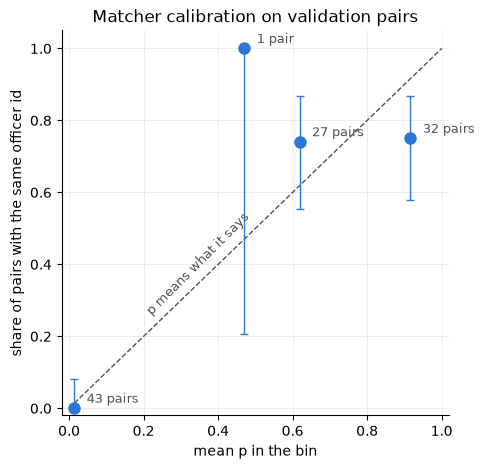

In [9]:
# The reliability plot: one dot per bin, with its 95% interval. On the dashed line, p means what it says.
share = reliability["same_officer_id"] / reliability["pairs"]
ends = [real_slice.wilson(int(k), int(n)) for k, n in zip(reliability["same_officer_id"], reliability["pairs"])]
below = [middle - low for middle, (low, high) in zip(share, ends)]
above = [high - middle for middle, (low, high) in zip(share, ends)]

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="#52514e")
ax.errorbar(reliability["mean_p"], share, yerr=[below, above], fmt="o", markersize=8, color="#2a78d6",
            elinewidth=1, capsize=3, zorder=3)
for x, middle, n in zip(reliability["mean_p"], share, reliability["pairs"]):
    ax.annotate(f"{n} pair" + ("s" if n != 1 else ""), (x, middle), textcoords="offset points",
                xytext=(9, 4), fontsize=9, color="#52514e")
ax.text(0.2, 0.26, "p means what it says", rotation=45, fontsize=9, color="#52514e")
ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.05), xlabel="mean p in the bin",
       ylabel="share of pairs with the same officer id", title="Matcher calibration on validation pairs")
ax.grid(color="#e5e4e0", linewidth=0.5)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**What it shows.** The weights make sense: agreeing on birth month and year counts most, then name, nationality and postcode district. `p` is right where it is low: 43 pairs under 0.2, none with the same officer id. Around 0.62 it holds (20 of 27, interval 55–87%). At the top it is **too sure**: 32 pairs with a mean `p` of 0.92, of which only 24 share an officer id (75%, interval 58–87%). Part of that gap may be the label rather than the matcher: two records that agree on name, birth, postcode and nationality but carry two officer ids may be one person the register split. The Brier score, 0.124, beats the bar of 0.273. With 103 validation pairs this is a first check, not a verdict, and `p` doesn't pass yet: by #88's rule it is a score, not a probability, until the hand check (#89) says more.

## The failure line (#33, #94)
Every candidate pair gets the matcher's `p`. For each company, `candidate_matches` keeps the pairs that tie one of its directors to someone who ran a company insolvent by its formation date, and P(predecessor) = 1 − ∏(1 − p). The straight line from P(predecessor) to the failure rate is fitted on the training companies only.

In [10]:
start = time.perf_counter()
scored = resolve.scored_pairs(model, candidates, mentions)
matches = {query: decide.candidate_matches(query, mentions, claims, scored) for query in labels["company_id"]}
p_pred = pd.Series({query: decide.company_p_predecessor(found) for query, found in matches.items()})
timings["matches and P(predecessor), every company"] = time.perf_counter() - start

print("P(predecessor) = 0:", int((p_pred == 0).sum()), "| above 0:", int((p_pred > 0).sum()),
      "| 0.5 or more:", int((p_pred >= 0.5).sum()), "| no director records:", int(p_pred.isna().sum()))

line = decide.fit_failure_line(p_pred.loc[train["company_id"]], train["failed"])
clear_below, flag_above = decide.thresholds(*COSTS)
print(f"the line, fitted on {len(train)} training companies: {line[0]:.1%} fail without an insolvent predecessor, "
      f"{line[1]:.1%} with one")
print(f"the costs {COSTS}: CLEAR at or below {clear_below:.0%}, FLAG at or above {flag_above:.0%}")
print("rate_with is below the FLAG threshold: FLAG can never fire" if line[1] < flag_above else "FLAG can fire")

P(predecessor) = 0: 361 | above 0: 77 | 0.5 or more: 31 | no director records: 0
the line, fitted on 331 training companies: 35.0% fail without an insolvent predecessor, 9.6% with one
the costs (10, 2, 1): CLEAR at or below 10%, FLAG at or above 50%
rate_with is below the FLAG threshold: FLAG can never fire


In [11]:
# 94: on validation, the line's prediction next to the real failure rate, in three groups of P(predecessor)
line_check = pd.DataFrame({"p_predecessor": p_pred.loc[validation["company_id"]].to_numpy(),
                           "failed": validation["failed"].to_numpy()})
line_check["predicted"] = [decide.p_fail(p, line) for p in line_check["p_predecessor"]]
groups = pd.cut(line_check["p_predecessor"], [-0.01, 0, 0.5, 1], labels=["0", "above 0, up to 0.5", "above 0.5"])
summary = line_check.groupby(groups, observed=True).agg(
    companies=("failed", "size"), failed=("failed", "sum"), predicted=("predicted", "mean"))
summary["really failed, with 95% interval"] = [real_slice.rate(int(k), int(n)) for k, n in zip(summary["failed"], summary["companies"])]
summary.round(2)

,companies,failed,predicted,"really failed, with 95% interval"
p_predecessor,,,,
0,91,23,0.35,23 of 91: 25% (17-35%)
"above 0, up to 0.5",7,2,0.34,2 of 7: 29% (8-64%)
above 0.5,9,1,0.13,1 of 9: 11% (2-44%)


**What it shows.** The line slopes **down**: 35.0% of training companies without an insolvent predecessor fail, against 9.6% at P(predecessor) = 1. So a likely predecessor *lowers* P(fail), and `rate_with` is below the FLAG threshold of 50%: **FLAG can never fire**, which #94 says to raise on the call. Validation points the same way, but on 9 companies: 1 of 9 failed above 0.5 (11%, interval 2–44%), against 23 of 91 at 0 (25%, 17–35%). The line also predicts 35% where validation shows 25%, because validation fails less often than train.

## The decision layer, on validation
FLAG, CLEAR or NOT ENOUGH EVIDENCE for each validation company, with the line above and the team's costs, scored next to the baselines by the same function.

In [12]:
start = time.perf_counter()
our_decisions = pd.DataFrame([decide.decide(query, matches[query], line, COSTS) for query in validation["company_id"]],
                             columns=ev.DECISION_COLS)
timings["decision layer on validation"] = time.perf_counter() - start

print(our_decisions["decision"].value_counts().to_dict())
print(f"share of validation companies that failed: {validation['failed'].mean():.3f} (what a PR-AUC with no signal gives)")
evaluate.score_methods(pd.concat([baseline_decisions, our_decisions], ignore_index=True), validation)

{'NOT ENOUGH EVIDENCE': 106, 'CLEAR': 1}
share of validation companies that failed: 0.243 (what a PR-AUC with no signal gives)


,method,companies,failed,flags,false_flags,misses,precision,recall,not_enough_evidence,pr_auc
0,flag_nothing,107,26,0,0,26,NaN,0.000000,0.000000,NaN
1,same_name,107,26,2,1,25,0.5,0.038462,0.000000,NaN
2,officer_links,107,26,0,0,26,NaN,0.000000,0.000000,NaN
3,formula,107,26,0,0,26,NaN,0.000000,0.990654,0.253317


**What it shows.** 106 of 107 validation companies get NOT ENOUGH EVIDENCE, and the one CLEAR is the company with the likeliest predecessor (below). The code does what it says; the numbers don't fit together. The label puts about a third of companies in "failed", and the line puts a company with no predecessor at 35%, between CLEAR at 10% and FLAG at 50%, so it can only land in between. The PR-AUC of 0.253 is about what no signal gives (0.243), and of the 26 failures only `same_name` catches one.

## show() for one real company
The validation company with the highest P(predecessor). Directors are pseudonyms; company names are shown, as the adapter's masking allows (#111).

13668751: CLEAR
13668751 may share a director with 03250164, an earlier company that went insolvent (92% sure it's the same person): its 10% chance of failing within two years is low enough to clear.


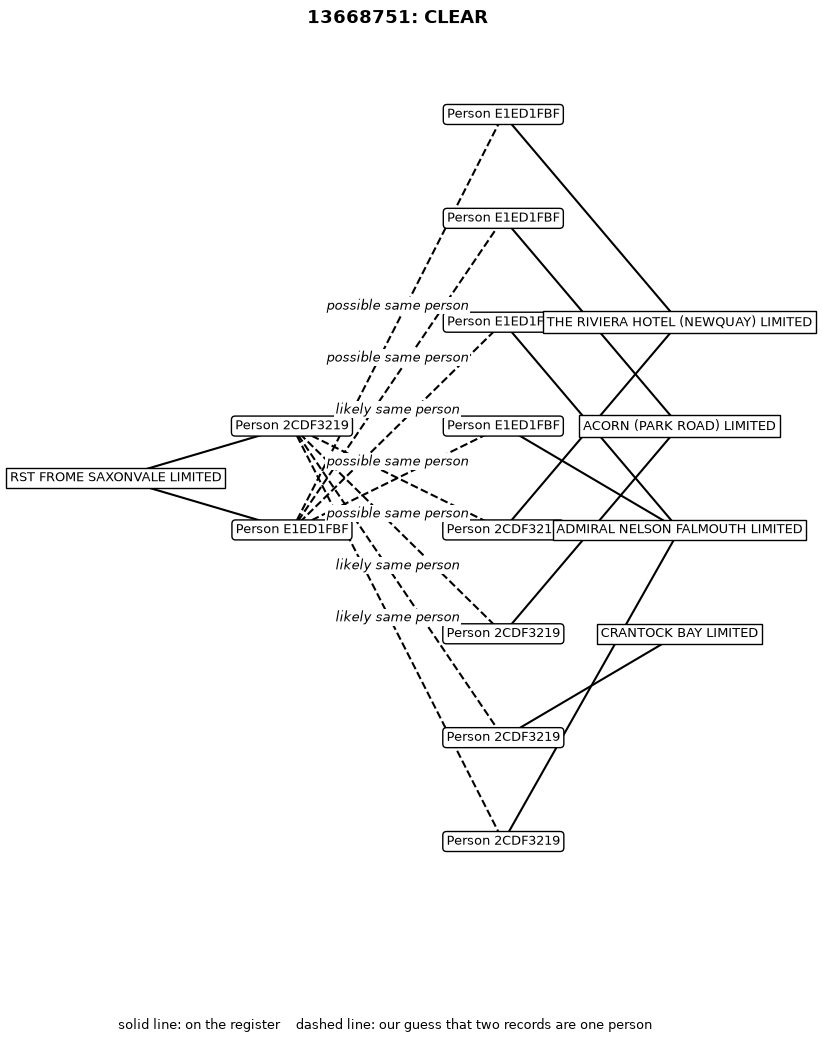

,line,from,to,says,how sure,p,source,record or depends on,check first
0,solid (fact),Person 2CDF3219,RST FROME SAXONVALE LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/13668751.json#0@8d864f8bdf13...,
1,solid (fact),Person E1ED1FBF,RST FROME SAXONVALE LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/13668751.json#1@8d864f8bdf13...,
2,solid (fact),Person E1ED1FBF,THE RIVIERA HOTEL (NEWQUAY) LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/06328919.json#1@89c11fdca5f1...,
3,solid (fact),Person E1ED1FBF,ACORN (PARK ROAD) LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/06032661.json#1@278743b34149...,
4,solid (fact),Person E1ED1FBF,ADMIRAL NELSON FALMOUTH LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/03250164.json#1@9c76726efaec...,
5,solid (fact),Person E1ED1FBF,ADMIRAL NELSON FALMOUTH LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/03250164.json#7@9c76726efaec...,
6,solid (fact),Person 2CDF3219,THE RIVIERA HOTEL (NEWQUAY) LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/06328919.json#3@89c11fdca5f1...,
7,solid (fact),Person 2CDF3219,ACORN (PARK ROAD) LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/06032661.json#4@278743b34149...,
8,solid (fact),Person 2CDF3219,CRANTOCK BAY LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/07831175.json#0@9b4632300fc0...,
9,solid (fact),Person 2CDF3219,ADMIRAL NELSON FALMOUTH LIMITED,director of,on the register,NaN,companies_house,data/raw/officers/03250164.json#6@9c76726efaec...,


In [13]:
example = p_pred.loc[validation["company_id"]].sort_values(ascending=False, kind="stable").index[0]
start = time.perf_counter()
row, fig, table = interface.show(example, mentions, claims, matches, our_decisions)
timings["show() for one company"] = time.perf_counter() - start

**What it shows.** Both directors of this company match records at insolvent earlier companies (`p` 0.62 and 0.92), and the decision is CLEAR, because the line says such companies fail less. Two things in the picture don't work yet on real data: with 8 guesses the labels overlap, and both ends of a guess show the same pseudonym, because the same name always gets the same pseudonym.

## The key table: does an insolvent predecessor raise the failure rate?
Every labelled company (train and validation; there is no test set yet), counted once, under the strongest link it has to an insolvent earlier company. The rule is the decision layer's: a director on record when the company was formed, paired with someone who was a director of a company insolvent by that date, with no time window. Each rate has its 95% Wilson interval.

In [14]:
start = time.perf_counter()
links = real_slice.link_pairs(mentions)
strongest = real_slice.strongest_link(labels["company_id"], mentions, claims, links)
timings["key table"] = time.perf_counter() - start

by_company = labels.set_index("company_id")
real_slice.rate_table(strongest, by_company["failed"], by_company["failed_insolvency"])

,strongest link to an insolvent earlier company,companies,failed (team label),failed through insolvency only
0,no predecessor,369,120 of 369: 33% (28-37%),0 of 369: 0% (0-1%)
1,same officer id,13,2 of 13: 15% (4-42%),0 of 13: 0% (0-23%)
2,same name and birth month and year,17,2 of 17: 12% (3-34%),0 of 17: 0% (0-18%)
3,same name only,39,13 of 39: 33% (21-49%),0 of 39: 0% (0-9%)


In [15]:
# The two links that point to the same person, taken together, and where the links fall by split
together = strongest.index[strongest.isin(["same officer id", "same name and birth month and year"])]
print("same officer id, or same name and birth month and year, together:",
      real_slice.rate(int(by_company.loc[together, "failed"].sum()), len(together)))
pd.crosstab(strongest.rename("strongest link"), by_company["split"])

same officer id, or same name and birth month and year, together: 4 of 30: 13% (5-30%)


split,train,validation
strongest link,,
no predecessor,275,94
same name and birth month and year,14,3
same name only,35,4
same officer id,7,6


**What it shows. No sign of it on this sample: the rate is lower, not higher.** Companies with a predecessor under the same officer id failed 2 of 13 times, and under the same name and birth month and year 2 of 17. Together that is 4 of 30 (13%, interval 5–30%), against 120 of 369 (33%, 28–37%) with no predecessor. The two intervals overlap only a little (28–30%), so the drop could still be chance. Same-name-only links, probably mostly namesakes, fail like companies with no predecessor (13 of 39, 33%). Through liquidation or administration, not one company in any row failed within 24 months, so the question the project asks, about insolvency, has no answer on this sample yet.

Where these counts could be wrong: the crawl reads each officer's first 50 appointments, and per director only the first 100 name-search results and at most 20 same-name officers, so some predecessors are never seen; a link by name and birth month and year can still be two people; and there is no time window, so an insolvency long before the company was formed counts too.

## Timings

In [16]:
pd.Series(timings, name="seconds").round(2).to_frame()

,seconds
"load the slice: adapter, checks, labels",0.83
three baselines on validation,1.95
blocking (#83),0.06
"matcher: labelled pairs, features, training",0.13
"matches and P(predecessor), every company",3.25
decision layer on validation,0.01
show() for one company,0.13
key table,8.81


## What breaks
Nothing crashes: every box runs on the real slice, and the whole notebook runs in under a minute. What doesn't work yet:
1. **The label and the costs don't fit.** With dissolution in the label, about a third of companies fail, and the line puts a company with no predecessor at 35%, between CLEAR (10%) and FLAG (50%). So the decision layer answers NOT ENOUGH EVIDENCE for 106 of 107 validation companies.
2. **The failure line slopes down** (35% to 9.6%). FLAG can never fire, and a likely predecessor makes a company look safer.
3. **No failure through insolvency** within 24 months among the 438 companies, so the phoenix question has no positives here.
4. **The baselines and the decision layer use different windows**: 3 years against none. `officer_links` flags no validation company with the window, and 6 without it, all false flags.
5. **The matcher is too sure at the top** (mean `p` 0.92, 75% same officer id), yet the reason reads "92% sure it's the same person".
6. **show()'s picture gets crowded** with 8 guesses: labels overlap, and both ends of a guess show the same pseudonym.
7. The adapter skips 2 director records whose resignation is dated before the appointment. That is a warning by design (#125), not a failure.